# Étape 7 — Phase B+ : diversité architecturale + stacking

**Constat Phase B** :
- 5-fold CV honnête = **0.001032** ≈ Phase A (0.001029) → +M3 +M4 n'apportent rien 
- Gap genre 38.9 % toujours présent

**Plan Phase B+** — 2 leviers complémentaires :

Diversité archi :  S5 = swin_tiny (transformer hiérarchique) + S6 = convnext_small  
Stacking LightGBM meta-learner avec features `[preds_modèles, gender, var]`

## 1. Setup 

In [1]:
import sys, time, pickle
from pathlib import Path

ROOT = Path.cwd()   # racine du depot (les notebooks sont a la racine)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

from dc_utils.paths import IMAGE_DIR, ARTIFACTS_DIR
from dc_utils.training import TrainConfig, train_model, OcclusionDataset, default_eval_tf
from dc_utils.metric import compute_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device, '| timm', timm.__version__)

EXP_DIR = ROOT / 'experiments'
df_train = pd.read_csv(ROOT / 'data' / 'train_split.csv')
df_val   = pd.read_csv(ROOT / 'data' / 'val_split.csv')
print('train:', len(df_train), '| val:', len(df_val))

class TimmRegressor(nn.Module):
    def __init__(self, backbone_name: str, pretrained: bool = True, bias_init: float | None = None):
        super().__init__()
        self.backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=1)
        if bias_init is not None:
            head = self.backbone.get_classifier()
            with torch.no_grad():
                head.bias.fill_(bias_init); head.weight.mul_(0.01)
    def forward(self, x):
        return torch.sigmoid(self.backbone(x)).squeeze(-1)

_p0 = float(df_train['FaceOcclusion'].mean())
HEAD_BIAS_INIT = float(np.log(_p0 / (1.0 - _p0)))
print(f'mean target = {_p0:.4f} | bias_init = {HEAD_BIAS_INIT:.4f}')

def fresh_model(backbone_name: str, seed: int = 42):
    torch.manual_seed(seed); np.random.seed(seed)
    m = TimmRegressor(backbone_name, bias_init=HEAD_BIAS_INIT).to(device)
    n = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'{backbone_name} (seed={seed}): {n/1e6:.2f}M params')
    return m

RESULTS: list[dict] = []
def log_run(name, history, best, notes=''):
    history.to_csv(EXP_DIR / f'history_{name}.csv', index=False)
    RESULTS.append({'name': name, 'best_epoch': best['epoch'], 'val_score': best['score'],
                    'err_F': best['err_F'], 'err_M': best['err_M'], 'gap': best['gap'], 'notes': notes})
    print(f'\n>>> {name}: val_score = {best["score"]:.5f} (epoch {best["epoch"]})\n')

<repo>/.venv/lib64/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device = cuda | timm 1.0.27
train: 89793 | val: 9977
mean target = 0.0827 | bias_init = -2.4069


## 2. S5 — swin_tiny_patch4_window7_224

Pourquoi un transformer ? Tous les modèles actuels (F1, F2, M3, M4) sont des **CNN**. Un Swin Transformer voit l'image différemment :
- mécanisme d'attention avec fenêtre locale → contexte spatial différent des convolutions
- biais inductifs orthogonaux → résidus moins corrélés avec ConvNeXt/EfficientNet
- 28M params (équivalent ConvNeXt-Tiny) → comparable en capacité

In [2]:
model = fresh_model('swin_tiny_patch4_window7_224', seed=42)
cfg = TrainConfig(epochs=8, lr=5e-5, weight_decay=1e-4, batch_size=64, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_S5_swin_tiny.pt', log_prefix='[S5] ',
)
log_run('S5_swin_tiny', hist, best, notes='swin_tiny_patch4_window7_224, lr=5e-5, 8ep, BS=64')

swin_tiny_patch4_window7_224 (seed=42): 27.52M params


decode 99770 imgs: 100%|██████████| 99770/99770 [02:50<00:00, 583.75it/s] 


  -> RAM cache: shape (99770, 224, 224, 3) | dtype uint8 | 15.02 GB (single ndarray, fork-safe)


[S5] ep 1 | loss 0.00227 | score 0.00162 | err_F 0.00116 | err_M 0.00147 | gap 0.00031 | 170s *


[S5] ep 2 | loss 0.00124 | score 0.00134 | err_F 0.00073 | err_M 0.00113 | gap 0.00041 | 167s *


...

[S5] ep 4 | loss 0.00079 | score 0.00138 | err_F 0.00066 | err_M 0.00114 | gap 0.00048 | 167s


[S5] ep 5 | loss 0.00065 | score 0.00145 | err_F 0.00077 | err_M 0.00123 | gap 0.00045 | 167s


[S5] ep 6 | loss 0.00052 | score 0.00110 | err_F 0.00054 | err_M 0.00092 | gap 0.00038 | 166s *


[S5] ep 7 | loss 0.00045 | score 0.00112 | err_F 0.00055 | err_M 0.00093 | gap 0.00038 | 167s


[S5] ep 8 | loss 0.00041 | score 0.00115 | err_F 0.00051 | err_M 0.00094 | gap 0.00042 | 167s

>>> S5_swin_tiny: val_score = 0.00110 (epoch 6)



## 3. S6 — `convnext_small`

In [3]:
model = fresh_model('convnext_small', seed=42)
cfg = TrainConfig(epochs=8, lr=1e-4, weight_decay=1e-4, batch_size=64, use_amp=True,
                  num_workers=4, cache_in_ram=True)
hist, best = train_model(
    model, df_train, df_val, IMAGE_DIR, cfg, device,
    save_path=ARTIFACTS_DIR / 'exp_S6_convnext_small.pt', log_prefix='[S6] ',
)
log_run('S6_convnext_small', hist, best, notes='convnext_small, lr=1e-4, 8ep, BS=64')

convnext_small (seed=42): 49.46M params


[S6] ep 1 | loss 0.00406 | score 0.00168 | err_F 0.00100 | err_M 0.00145 | gap 0.00045 | 225s *


[S6] ep 2 | loss 0.00139 | score 0.00249 | err_F 0.00165 | err_M 0.00221 | gap 0.00056 | 220s


[S6] ep 3 | loss 0.00112 | score 0.00134 | err_F 0.00060 | err_M 0.00109 | gap 0.00049 | 220s *


[S6] ep 4 | loss 0.00086 | score 0.00137 | err_F 0.00095 | err_M 0.00123 | gap 0.00028 | 220s


[S6] ep 5 | loss 0.00066 | score 0.00137 | err_F 0.00054 | err_M 0.00109 | gap 0.00055 | 221s


[S6] ep 6 | loss 0.00058 | score 0.00130 | err_F 0.00050 | err_M 0.00104 | gap 0.00053 | 220s *


[S6] ep 7 | loss 0.00036 | score 0.00135 | err_F 0.00048 | err_M 0.00106 | gap 0.00058 | 219s


[S6] ep 8 | loss 0.00030 | score 0.00126 | err_F 0.00042 | err_M 0.00098 | gap 0.00056 | 220s *

>>> S6_convnext_small: val_score = 0.00126 (epoch 8)



## 4. Reload des 6 modèles

In [4]:
def load_ckpt(backbone_name: str, ckpt_path: Path) -> nn.Module:
    m = TimmRegressor(backbone_name, pretrained=False).to(device)
    state = torch.load(ckpt_path, map_location=device, weights_only=False)
    m.load_state_dict(state['model'])
    m.eval()
    print(f'loaded {ckpt_path.name} | best ep={state.get("epoch")} | val={state.get("val")}')
    return m

models = {
    'F1_effb0':           load_ckpt('efficientnet_b0',                ARTIFACTS_DIR / 'exp_F1_effb0.pt'),
    'F2_convnext':        load_ckpt('convnext_tiny',                  ARTIFACTS_DIR / 'exp_F2_convnext.pt'),
    'M3_convnext_seed1':  load_ckpt('convnext_tiny',                  ARTIFACTS_DIR / 'exp_M3_convnext_seed1.pt'),
    'M4_effb3':           load_ckpt('efficientnet_b3',                ARTIFACTS_DIR / 'exp_M4_effb3.pt'),
    'S5_swin_tiny':       load_ckpt('swin_tiny_patch4_window7_224',   ARTIFACTS_DIR / 'exp_S5_swin_tiny.pt'),
    'S6_convnext_small':  load_ckpt('convnext_small',                 ARTIFACTS_DIR / 'exp_S6_convnext_small.pt'),
}

loaded exp_F1_effb0.pt | best ep=7 | val={'score': 0.0012036067644963949, 'err_F': 0.0007178655938697917, 'err_M': 0.0010416930409541938, 'gap': 0.0003238274470844021, 'n_F': 3229, 'n_M': 6748}
loaded exp_F2_convnext.pt | best ep=7 | val={'score': 0.0011637669447581373, 'err_F': 0.0004344179381005615, 'err_M': 0.0009206506092056121, 'gap': 0.0004862326711050506, 'n_F': 3229, 'n_M': 6748}
loaded exp_M3_convnext_seed1.pt | best ep=6 | val={'score': 0.001163342516329837, 'err_F': 0.0004891343568363376, 'err_M': 0.0009386064631653372, 'gap': 0.00044947210632899956, 'n_F': 3229, 'n_M': 6748}
loaded exp_M4_effb3.pt | best ep=5 | val={'score': 0.001400681703104405, 'err_F': 0.0007861337694553754, 'err_M': 0.0011958323918880617, 'gap': 0.00040969862243268624, 'n_F': 3229, 'n_M': 6748}
loaded exp_S5_swin_tiny.pt | best ep=6 | val={'score': 0.0011033255146374885, 'err_F': 0.000539469811541658, 'err_M': 0.0009153736136055451, 'gap': 0.0003759038020638871, 'n_F': 3229, 'n_M': 6748}
loaded exp_S6_c

## 5. Prédictions val TTA pour les 6 modèles

In [5]:
@torch.inference_mode()
def predict(model, dl, device, tta_flip: bool = False, use_amp: bool = True):
    model.eval()
    preds, fns = [], []
    ctx = torch.amp.autocast('cuda', enabled=use_amp)
    for batch in dl:
        X = batch[0].to(device, non_blocking=True)
        fn = batch[-1]
        with ctx:
            p = model(X).float()
            if tta_flip:
                p_flip = model(torch.flip(X, dims=[-1])).float()
                p = 0.5 * (p + p_flip)
        preds.append(p.cpu().numpy()); fns.extend(fn)
    return np.concatenate(preds), fns

ds_val = OcclusionDataset(df_val, IMAGE_DIR, default_eval_tf(), has_target=True)
dl_val = DataLoader(ds_val, batch_size=256, shuffle=False, num_workers=4, pin_memory=True)

# Récupère l'ordre filenames (1 forward sans TTA juste pour ça)
_, FILENAMES = predict(next(iter(models.values())), dl_val, device, tta_flip=False)

PREDS = {}
for name, m in models.items():
    t0 = time.time()
    p, fns = predict(m, dl_val, device, tta_flip=True)
    assert fns == FILENAMES, 'order mismatch'
    PREDS[name] = p
    df_p = pd.DataFrame({'filename': FILENAMES, 'pred': p}).merge(
        df_val[['filename','FaceOcclusion','gender']].rename(columns={'FaceOcclusion':'target'}), on='filename')
    s = compute_score(df_p)
    print(f'{name:22s} TTA | score {s["score"]:.5f} | err_F {s["err_F"]:.5f} | err_M {s["err_M"]:.5f} | gap {s["gap"]:.5f} | {time.time()-t0:.0f}s')

F1_effb0               TTA | score 0.00119 | err_F 0.00070 | err_M 0.00102 | gap 0.00033 | 63s
F2_convnext            TTA | score 0.00113 | err_F 0.00043 | err_M 0.00089 | gap 0.00047 | 17s
M3_convnext_seed1      TTA | score 0.00115 | err_F 0.00046 | err_M 0.00092 | gap 0.00046 | 17s
M4_effb3               TTA | score 0.00139 | err_F 0.00073 | err_M 0.00117 | gap 0.00044 | 19s
S5_swin_tiny           TTA | score 0.00111 | err_F 0.00052 | err_M 0.00092 | gap 0.00039 | 16s
S6_convnext_small      TTA | score 0.00122 | err_F 0.00041 | err_M 0.00095 | gap 0.00054 | 17s


## 6. Matrice de corrélation des résidus (6 modèles)

L'objectif : voir si S5 (swin) est vraiment décorrélé des CNN. Si corr(S5, F2) < 0.85, jackpot.

Corrélation des résidus (1 = redondants, 0 = orthogonaux) :
                   F1_effb0  F2_convnext  M3_convnext_seed1  M4_effb3  \
F1_effb0              1.000        0.712              0.724     0.782   
F2_convnext           0.712        1.000              0.857     0.694   
M3_convnext_seed1     0.724        0.857              1.000     0.729   
M4_effb3              0.782        0.694              0.729     1.000   
S5_swin_tiny          0.756        0.811              0.810     0.748   
S6_convnext_small     0.705        0.889              0.868     0.717   

                   S5_swin_tiny  S6_convnext_small  
F1_effb0                  0.756              0.705  
F2_convnext               0.811              0.889  
M3_convnext_seed1         0.810              0.868  
M4_effb3                  0.748              0.717  
S5_swin_tiny              1.000              0.811  
S6_convnext_small         0.811              1.000  


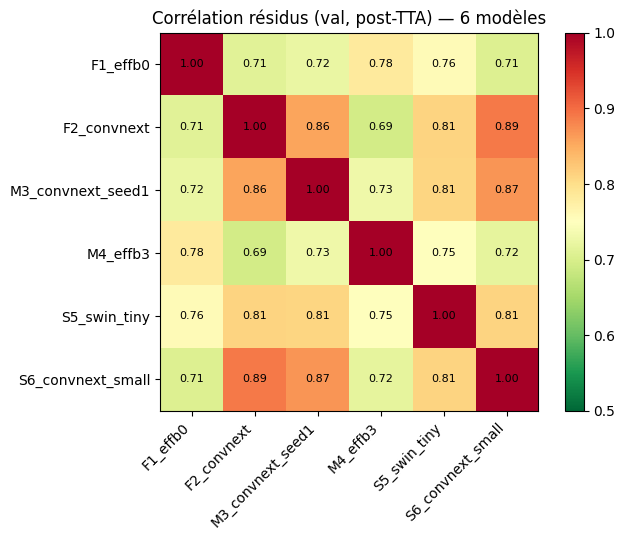


>>> Plus faible corrélation hors diagonale :
F2_convnext        M4_effb3             0.693752
M4_effb3           F2_convnext          0.693752
S6_convnext_small  F1_effb0             0.705127
F1_effb0           S6_convnext_small    0.705127
                   F2_convnext          0.711950
dtype: float64


In [6]:
target = df_val.set_index('filename').loc[FILENAMES, 'FaceOcclusion'].values
gender = df_val.set_index('filename').loc[FILENAMES, 'gender'].values
y = target

residuals = pd.DataFrame({n: PREDS[n] - target for n in PREDS})
corr = residuals.corr()
print('Corrélation des résidus (1 = redondants, 0 = orthogonaux) :')
print(corr.round(3))

fig, ax = plt.subplots(figsize=(7,5.5))
im = ax.imshow(corr.values, vmin=0.5, vmax=1.0, cmap='RdYlGn_r')
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im); ax.set_title('Corrélation résidus (val, post-TTA) — 6 modèles')
plt.tight_layout(); plt.show()

print('\n>>> Plus faible corrélation hors diagonale :')
c = corr.where(~np.eye(len(corr), dtype=bool)).stack().sort_values()
print(c.head(5))

## 7. Ensemble pondéré 6 modèles

In [ ]:
from scipy.optimize import minimize
from sklearn.model_selection import KFold

names = list(PREDS.keys())
P = np.stack([PREDS[n] for n in names])    # (M, N)

def score_from_weights(w, P=P, y=y, gender=gender):
    p = (w[:,None] * P).sum(axis=0)
    return compute_score(pd.DataFrame({'pred': p, 'target': y, 'gender': gender}))['score']

def optimize_weights(P_arr, y_arr, g_arr, x0=None):
    M = P_arr.shape[0]
    if x0 is None: x0 = np.ones(M) / M
    cons = [{'type': 'eq', 'fun': lambda w: w.sum() - 1.0}]
    bnds = [(0.0, 1.0)] * M
    return minimize(
        lambda w: compute_score(pd.DataFrame({
            'pred': (w[:,None]*P_arr).sum(0), 'target': y_arr, 'gender': g_arr})
        )['score'],
        x0=x0, method='SLSQP', bounds=bnds, constraints=cons,
        options={'ftol': 1e-9, 'maxiter': 300},
    )

# (1) Optimisation sur 100% val (optimiste)
res_full = optimize_weights(P, y, gender)
w_full = res_full.x
print('=== Poids optimaux (val 100%) ===')
for n, w in zip(names, w_full):
    print(f'  {n:22s} : {w:.3f}')
print(f'Score ensemble pondéré (val full)  : {res_full.fun:.5f}')

# (2) Référence uniforme
w_uniform = np.ones(len(names)) / len(names)
print(f'Score ensemble uniforme (6)        : {score_from_weights(w_uniform):.5f}')

# (3) 5-fold CV
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred = np.full(len(y), np.nan)
oof_weights = []
for k, (tr, te) in enumerate(kf.split(np.arange(len(y)))):
    res_k = optimize_weights(P[:, tr], y[tr], gender[tr])
    oof_weights.append(res_k.x)
    oof_pred[te] = (res_k.x[:,None] * P[:, te]).sum(axis=0)

oof_score_w = compute_score(pd.DataFrame({'pred': oof_pred, 'target': y, 'gender': gender}))
print(f'\n=== ENS_6weighted_5foldCV ===')
print(f'Score : {oof_score_w["score"]:.5f} | err_F {oof_score_w["err_F"]:.5f} | err_M {oof_score_w["err_M"]:.5f} | gap {oof_score_w["gap"]:.5f}')

w_mean = np.mean(oof_weights, axis=0)
w_std  = np.std(oof_weights, axis=0)
print(f'\nPoids moyens 5-fold (stabilité):')
for n, m, s in zip(names, w_mean, w_std):
    print(f'  {n:22s} : {m:.3f} ± {s:.3f}')

=== Poids optimaux (val 100%) ===
  F1_effb0               : 0.350
  F2_convnext            : 0.186
  M3_convnext_seed1      : 0.181
  M4_effb3               : 0.000
  S5_swin_tiny           : 0.281
  S6_convnext_small      : 0.001
Score ensemble pondéré (val full)  : 0.00099
Score ensemble uniforme (6)        : 0.00102

=== ENS_6weighted_5foldCV ===
Score : 0.00101 | err_F 0.00043 | err_M 0.00082 | gap 0.00038

Poids moyens 5-fold (stabilité):
  F1_effb0               : 0.337 ± 0.023
  F2_convnext            : 0.180 ± 0.061
  M3_convnext_seed1      : 0.179 ± 0.046
  M4_effb3               : 0.007 ± 0.014
  S5_swin_tiny           : 0.273 ± 0.032
  S6_convnext_small      : 0.024 ± 0.029


## 8. Stacking LightGBM

**Idée clé** : la moyenne pondérée `Σ wᵢ · pᵢ` impose **les mêmes poids pour H et F**. Or, le gap genre vient de ce que les hommes ont des erreurs structurellement plus grandes. Un meta-learner qui voit le **`gender`** comme feature peut apprendre des combinaisons différenciées.

**Features** (par échantillon val) :
- 6 prédictions des modèles
- `gender` (0/1)
- statistiques de désaccord : `mean`, `std`, `min`, `max` des 6 preds

**Cible** : `FaceOcclusion` (régression), loss MSE pondérée par les $w_i = 1/30 + GT_i$

**Validation** : 5-fold CV (mêmes splits que la moyenne pondérée)

In [8]:
import lightgbm as lgb

def build_features(P_arr: np.ndarray, gender_arr: np.ndarray) -> pd.DataFrame:
    """P_arr shape (M, N) -> N x (M+5) features."""
    M, N = P_arr.shape
    feats = {f'pred_{names[i]}': P_arr[i] for i in range(M)}
    feats['gender']   = gender_arr.astype(np.float32)
    feats['p_mean']   = P_arr.mean(axis=0)
    feats['p_std']    = P_arr.std(axis=0)
    feats['p_min']    = P_arr.min(axis=0)
    feats['p_max']    = P_arr.max(axis=0)
    feats['p_range']  = feats['p_max'] - feats['p_min']
    return pd.DataFrame(feats)

X_full = build_features(P, gender)
print(f'Features shape : {X_full.shape}')
print(X_full.head(3))

# Poids loss alignés sur la métrique : w_i = 1/30 + GT_i
sample_w = (1.0/30.0 + y).astype(np.float32)

# 5-fold CV stacking honnête (mêmes splits que ensemble pondéré)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_pred_stk = np.full(len(y), np.nan)
gbms = []
for k, (tr, te) in enumerate(kf.split(np.arange(len(y)))):
    dtr = lgb.Dataset(X_full.iloc[tr], label=y[tr], weight=sample_w[tr])
    dte = lgb.Dataset(X_full.iloc[te], label=y[te], weight=sample_w[te], reference=dtr)
    params = dict(
        objective='regression',          # MSE pondérée
        learning_rate=0.02,
        num_leaves=15,
        max_depth=4,
        min_data_in_leaf=200,
        feature_fraction=0.8,
        bagging_fraction=0.8,
        bagging_freq=5,
        lambda_l2=1.0,
        verbose=-1,
        metric='mse',
    )
    gbm = lgb.train(
        params, dtr, num_boost_round=2000,
        valid_sets=[dte],
        callbacks=[lgb.early_stopping(80), lgb.log_evaluation(0)],
    )
    pred_te = gbm.predict(X_full.iloc[te], num_iteration=gbm.best_iteration)
    pred_te = np.clip(pred_te, 0.0, 1.0)
    oof_pred_stk[te] = pred_te
    gbms.append(gbm)
    print(f'fold {k}: best_iter={gbm.best_iteration}')

oof_score_stk = compute_score(pd.DataFrame({'pred': oof_pred_stk, 'target': y, 'gender': gender}))
print(f'\n=== STACKING LightGBM 5-fold CV ===')
print(f'Score : {oof_score_stk["score"]:.5f} | err_F {oof_score_stk["err_F"]:.5f} | err_M {oof_score_stk["err_M"]:.5f} | gap {oof_score_stk["gap"]:.5f}')

imp = np.mean([g.feature_importance(importance_type='gain') for g in gbms], axis=0)
imp_df = pd.DataFrame({'feature': X_full.columns, 'gain': imp}).sort_values('gain', ascending=False)
print('\nTop features (gain moyen) :')
print(imp_df.to_string(index=False))


Features shape : (9977, 12)
   pred_F1_effb0  pred_F2_convnext  pred_M3_convnext_seed1  pred_M4_effb3  \
0       0.036163          0.031418                0.040878       0.032867   
1       0.085693          0.079926                0.079620       0.068512   
2       0.026161          0.011894                0.022911       0.017883   

   pred_S5_swin_tiny  pred_S6_convnext_small  gender    p_mean     p_std  \
0           0.043121                0.031792     1.0  0.036040  0.004529   
1           0.077118                0.083374     0.0  0.079041  0.005458   
2           0.018425                0.013718     1.0  0.018499  0.004917   

      p_min     p_max   p_range  
0  0.031418  0.043121  0.011703  
1  0.068512  0.085693  0.017181  
2  0.011894  0.026161  0.014267  
Training until validation scores don't improve for 80 rounds
Early stopping, best iteration is:
[450]	valid_0's l2: 0.000868785
fold 0: best_iter=450
Training until validation scores don't improve for 80 rounds
Early stopp

## 9. Hybride : moyenne pondérée + stacking

On cherche le meilleur ratio $\alpha \in [0,1]$ où $p_{final} = \alpha \cdot p_{stk} + (1-\alpha) \cdot p_{wgt}$, en 5-fold CV.

Meilleur blend : alpha=0.40 (alpha=1 -> stacking only, 0 -> weighted only)
Score blend best : 0.00100
  err_F 0.00041 | err_M 0.00081 | gap 0.00039


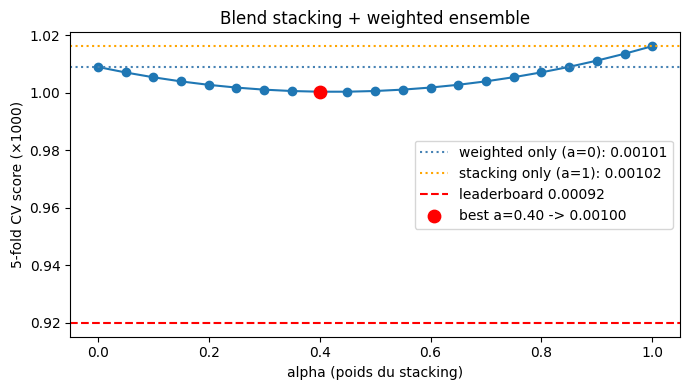

In [ ]:
alphas = np.linspace(0, 1, 21)
scores = []
for a in alphas:
    p_blend = a * oof_pred_stk + (1 - a) * oof_pred
    s = compute_score(pd.DataFrame({'pred': p_blend, 'target': y, 'gender': gender}))['score']
    scores.append(s)
scores = np.array(scores)

best_a = alphas[scores.argmin()]
best_s = scores.min()
print(f'Meilleur blend : alpha={best_a:.2f} (alpha=1 -> stacking only, 0 -> weighted only)')
print(f'Score blend best : {best_s:.5f}')

p_blend_best = best_a * oof_pred_stk + (1 - best_a) * oof_pred
oof_score_blend = compute_score(pd.DataFrame({'pred': p_blend_best, 'target': y, 'gender': gender}))
print(f'  err_F {oof_score_blend["err_F"]:.5f} | err_M {oof_score_blend["err_M"]:.5f} | gap {oof_score_blend["gap"]:.5f}')

fig, ax = plt.subplots(figsize=(7,4))
ax.plot(alphas, scores * 1000, marker='o')
ax.axhline(oof_score_w['score']*1000,   ls=':',  color='steelblue', label=f'weighted only (a=0): {oof_score_w["score"]:.5f}')
ax.axhline(oof_score_stk['score']*1000, ls=':',  color='orange',     label=f'stacking only (a=1): {oof_score_stk["score"]:.5f}')
ax.axhline(0.00092*1000, ls='--', color='red', label='leaderboard 0.00092')
ax.scatter([best_a], [best_s*1000], color='red', s=80, zorder=5, label=f'best a={best_a:.2f} -> {best_s:.5f}')
ax.set_xlabel('alpha (poids du stacking)'); ax.set_ylabel('5-fold CV score (×1000)')
ax.set_title('Blend stacking + weighted ensemble')
ax.legend(); plt.tight_layout(); plt.show()

## 10. Tableau de synthèse

In [10]:
rows = []

# Phase A best (ref)
phaseA = pd.read_csv(EXP_DIR / 'step5_phaseA_recipes.csv').iloc[0].to_dict()
rows.append({'recipe': 'PhaseA (ENS_0.4F1+0.6F2_TTA)', 'score': phaseA['score'],
             'err_F': phaseA['err_F'], 'err_M': phaseA['err_M'], 'gap': phaseA['gap']})

# Phase B best CV (5-fold)
phaseB = pd.read_csv(EXP_DIR / 'step6_phaseB_recipes.csv')
pb_row = phaseB[phaseB['recipe'] == 'ENS_4weighted_5foldCV_TTA'].iloc[0]
rows.append({'recipe': 'PhaseB (ENS_4weighted_5foldCV)', 'score': pb_row['score'],
             'err_F': pb_row['err_F'], 'err_M': pb_row['err_M'], 'gap': pb_row['gap']})

# Solos TTA des 6 modèles
for n in names:
    s = compute_score(pd.DataFrame({'pred': PREDS[n], 'target': y, 'gender': gender}))
    rows.append({'recipe': f'{n}_TTA', **{k: s[k] for k in ['score','err_F','err_M','gap']}})

# Uniforme 6
p_uni = (w_uniform[:,None] * P).sum(axis=0)
s_uni = compute_score(pd.DataFrame({'pred': p_uni, 'target': y, 'gender': gender}))
rows.append({'recipe': 'ENS_6uniform_TTA', **{k: s_uni[k] for k in ['score','err_F','err_M','gap']}})

# Pondéré 6 (full = optimiste)
p_full = (w_full[:,None] * P).sum(axis=0)
s_full = compute_score(pd.DataFrame({'pred': p_full, 'target': y, 'gender': gender}))
rows.append({'recipe': 'ENS_6weighted_full_TTA (optim.)',
             **{k: s_full[k] for k in ['score','err_F','err_M','gap']}})

# Pondéré 6 (5-fold honnête)
rows.append({'recipe': 'ENS_6weighted_5foldCV_TTA',
             **{k: oof_score_w[k] for k in ['score','err_F','err_M','gap']}})

# Stacking LightGBM (5-fold honnête)
rows.append({'recipe': 'STACK_LGBM_5foldCV_TTA',
             **{k: oof_score_stk[k] for k in ['score','err_F','err_M','gap']}})

# Blend (5-fold honnête)
rows.append({'recipe': f'BLEND_a={best_a:.2f}_5foldCV_TTA',
             **{k: oof_score_blend[k] for k in ['score','err_F','err_M','gap']}})

df_phBp = pd.DataFrame(rows).sort_values('score').reset_index(drop=True)
df_phBp['gap_%'] = (df_phBp['gap'] / df_phBp['score'] * 100).round(1)
ref = phaseA['score']
df_phBp['gain_vs_PhA'] = df_phBp['score'] - ref
df_phBp['gain_%']      = (-df_phBp['gain_vs_PhA'] / ref * 100).round(2)
df_phBp.to_csv(EXP_DIR / 'step7_phaseBplus_recipes.csv', index=False)
df_phBp

,recipe,score,err_F,err_M,gap,gap_%,gain_vs_PhA,gain_%
0,ENS_6weighted_full_TTA (optim.),0.000991,0.000435,0.000806,0.000371,37.4,-0.000038,3.65
1,BLEND_a=0.40_5foldCV_TTA,0.001000,0.000415,0.000805,0.000390,39.0,-0.000028,2.77
2,ENS_6weighted_5foldCV_TTA,0.001009,0.000434,0.000817,0.000383,38.0,-0.000020,1.93
3,STACK_LGBM_5foldCV_TTA,0.001016,0.000447,0.000826,0.000380,37.4,-0.000013,1.23
4,ENS_6uniform_TTA,0.001022,0.000407,0.000817,0.000410,40.1,-0.000007,0.69
5,PhaseA (ENS_0.4F1+0.6F2_TTA),0.001029,0.000435,0.000831,0.000396,38.5,0.000000,-0.00
6,PhaseB (ENS_4weighted_5foldCV),0.001032,0.000429,0.000831,0.000402,38.9,0.000004,-0.35
7,S5_swin_tiny_TTA,0.001115,0.000522,0.000917,0.000395,35.4,0.000086,-8.36
8,F2_convnext_TTA,0.001129,0.000426,0.000895,0.000469,41.5,0.000100,-9.76
9,M3_convnext_seed1_TTA,0.001152,0.000456,0.000920,0.000464,40.3,0.000123,-11.97
